In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
import joblib

sys.path.append(os.path.abspath('..'))
from src.transformadores import LimpiadorFormatosKaggle, CalculadorDistancia
from src.pipeline import construir_pipeline_preprocesamiento

In [2]:
print("=====================================================================")
print("         CARGA DE DATOS Y SEPARACIÓN DE VARIABLES")
print("=====================================================================\n")

# Cargar splits procesados (estratificados)
train_path = os.path.join('..', 'data', 'processed', 'train_processed.csv')
test_path = os.path.join('..', 'data', 'processed', 'test_processed.csv')

df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)

# Instanciamos los transformadores personalizados
limpiador = LimpiadorFormatosKaggle()
calculador = CalculadorDistancia()

# Aplicamos los transformadores base (Regex y Haversine) para limpiar el dataset general
df_train_final = calculador.transform(limpiador.transform(df_train))
df_test_final = calculador.transform(limpiador.transform(df_test))

# Separamos X (predictoras) e Y (objetivo)
X_train = df_train_final.drop(columns=['Time_taken(min)'])
y_train = df_train_final['Time_taken(min)'].astype(str).str.extract(r'(\d+\.?\d*)')[0].astype(float)

X_test = df_test_final.drop(columns=['Time_taken(min)'])
y_test = df_test_final['Time_taken(min)'].astype(str).str.extract(r'(\d+\.?\d*)')[0].astype(float)

print("Datos separados y listos para la Tubería MLOps.")

         CARGA DE DATOS Y SEPARACIÓN DE VARIABLES

Datos separados y listos para la Tubería MLOps.


In [3]:
print("=====================================================================")
print("      ENTRENAMIENTO Y VALIDACIÓN CRUZADA ESTRICTA")
print("=====================================================================\n")

# Construimos LA MEGA TUBERÍA que encapsula todo
pipeline_lr = Pipeline(steps=[
    ('preprocesador', construir_pipeline_preprocesamiento()),
    ('modelo_regresion', LinearRegression())
])

print("Entrenando Modelo de Regresión Lineal...")
# Un solo FIT hace todo: imputa, escala, codifica y entrena
pipeline_lr.fit(X_train, y_train)

# Evaluación en Test Set
y_pred_test_lr = pipeline_lr.predict(X_test)
mae_lr = mean_absolute_error(y_test, y_pred_test_lr)
r2_lr = r2_score(y_test, y_pred_test_lr)

print("--- MÉTRICAS TEST SET ---")
print(f"MAE: {mae_lr:.2f} minutos")
print(f"R2:  {r2_lr:.4f}\n")

print("Ejecutando K-Fold Cross Validation (K=5)...")
# Aquí le pasamos la TUBERÍA COMPLETA, asegurando cero Data Leakage
scores_mae_lr = -cross_val_score(pipeline_lr, X_train, y_train, cv=5, scoring='neg_mean_absolute_error')
print(f"MAE Promedio K-Fold: {scores_mae_lr.mean():.2f} minutos (+/- {scores_mae_lr.std():.2f} min)")

      ENTRENAMIENTO Y VALIDACIÓN CRUZADA ESTRICTA

Entrenando Modelo de Regresión Lineal...
--- MÉTRICAS TEST SET ---
MAE: 4.94 minutos
R2:  0.5518

Ejecutando K-Fold Cross Validation (K=5)...
MAE Promedio K-Fold: 4.97 minutos (+/- 0.05 min)


                 DIAGNÓSTICO VISUAL DEL MODELO



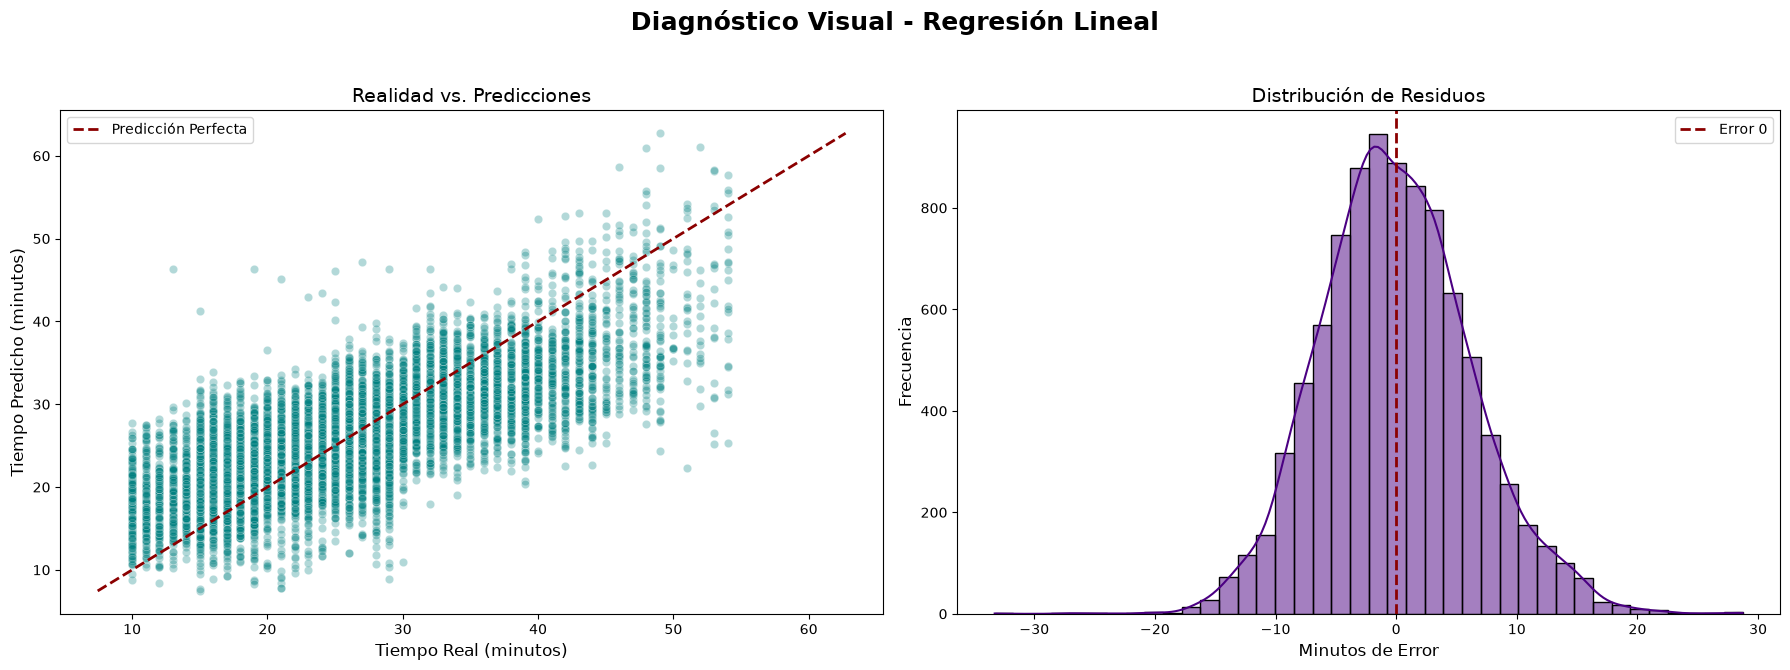

In [4]:
print("=====================================================================")
print("                 DIAGNÓSTICO VISUAL DEL MODELO")
print("=====================================================================\n")

residuos_lr = y_test - y_pred_test_lr

fig, ax = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Diagnóstico Visual - Regresión Lineal', fontsize=18, fontweight='bold')

# Gráfico 1: Real vs Predicho
sns.scatterplot(x=y_test, y=y_pred_test_lr, alpha=0.3, color='teal', ax=ax[0])
min_val = min(y_test.min(), y_pred_test_lr.min())
max_val = max(y_test.max(), y_pred_test_lr.max())
ax[0].plot([min_val, max_val], [min_val, max_val], color='darkred', linestyle='--', linewidth=2, label='Predicción Perfecta')
ax[0].set_title('Realidad vs. Predicciones', fontsize=14)
ax[0].set_xlabel('Tiempo Real (minutos)', fontsize=12)
ax[0].set_ylabel('Tiempo Predicho (minutos)', fontsize=12)
ax[0].legend()

# Gráfico 2: Campana de Errores
sns.histplot(residuos_lr, kde=True, color='indigo', bins=40, ax=ax[1])
ax[1].axvline(0, color='darkred', linestyle='--', linewidth=2, label='Error 0')
ax[1].set_title('Distribución de Residuos', fontsize=14)
ax[1].set_xlabel('Minutos de Error', fontsize=12)
ax[1].set_ylabel('Frecuencia', fontsize=12)
ax[1].legend()

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [5]:
print("=====================================================================")
print("     SERIALIZACIÓN (EXPORTACIÓN DEL MODELO Y PIPELINE)")
print("=====================================================================\n")

ruta_modelo_lr = os.path.join('..', 'models', 'modelo_regresion_lineal.joblib')

# Al serializar `pipeline_lr`, guardamos tanto el preprocesador como la regresión
joblib.dump(pipeline_lr, ruta_modelo_lr)

print(f"✓ Modelo Base MLOps serializado en:\n{ruta_modelo_lr}")

     SERIALIZACIÓN (EXPORTACIÓN DEL MODELO Y PIPELINE)

✓ Modelo Base MLOps serializado en:
..\models\modelo_regresion_lineal.joblib
